# Track-MJX: from observed motion to a control policy

We will use a trained policy to reproduce a recorded rodent movement in simulation.
The reference gives the desired motion. The policy chooses actuator commands, and
the simulator computes how the body moves. We will compare the two trajectories,
inspect the policy's internal activity, then repeat the analysis across three clips.

The overall workflow has three parts: STAC-MJX fits reference motion to a body model;
VNL Playground supplies the body and simulation task; Track-MJX trains and
evaluates the controller. Here we start with a released controller, so no training
run or W&B account is needed.

Sections 1–4 restore the policy and produce a video. Sections 5–7 measure tracking,
inspect activations, and compare several clips. Section 8 describes training and
task transfer. The code is complete: select the project kernel, then **Restart
Kernel and Run All**.

## 1. Prepare the workspace

Use Python 3.12 and the repository's environment, which includes the VNL 0.0.15
reference APIs. From the repository root:

```bash
uv sync --extra cuda13          # use cuda12 instead if appropriate for your system
source .venv/bin/activate
python -m ipykernel install --user --name track-mjx --display-name "Python (track-mjx)"
```

Select that kernel and run from the repository root or its `notebooks/` directory.
Both checkpoints have been tested on a local NVIDIA GPU with EGL rendering.
For device or rendering problems, see [test_setup.ipynb](test_setup.ipynb).
The JAX simulator can also run on a CPU, but it can be much slower.

The first run downloads the policy and about 482 MiB of reference motion.
Later runs reuse these files. We print package versions and the selected device
below. Renderer and memory settings must precede the JAX and MuJoCo imports;
restart the kernel if you change them.

In [1]:
import os
import sys

os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")
os.environ.setdefault("MUJOCO_GL", "glfw" if sys.platform == "darwin" else "egl")

import importlib.metadata as metadata
import time
from pathlib import Path

import huggingface_hub as hf
import imageio_ffmpeg
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import mediapy as media
import mujoco
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.decomposition import PCA

from track_mjx.agent import checkpointing
from track_mjx.analysis import rollout
from track_mjx.config import utils as config_utils
from track_mjx.device_utils import enable_jit_cache

enable_jit_cache()
media.set_ffmpeg(imageio_ffmpeg.get_ffmpeg_exe())
plt.rcParams.update(
    {
        "figure.dpi": 120,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.labelsize": 11,
        "axes.titlesize": 12,
        "font.size": 10,
    }
)

repo_root = next(
    (
        p
        for p in (Path.cwd(), *Path.cwd().parents)
        if (p / "track_mjx" / "version.py").is_file()
    ),
    None,
)
if repo_root is None:
    raise FileNotFoundError("Open this notebook from the track-mjx repository.")

versions = {
    name: metadata.version(name)
    for name in (
        "track-mjx",
        "vnl-playground",
        "jax",
        "jaxlib",
        "mujoco",
        "mujoco-mjx",
        "warp-lang",
        "orbax-checkpoint",
    )
}
display(pd.Series(versions, name="installed version").to_frame())
print("Python:", sys.version.split()[0])
print("JAX backend:", jax.default_backend())
print("Devices:", [device.device_kind for device in jax.devices()])
print("Renderer:", os.environ["MUJOCO_GL"])
jnp.sum(jnp.ones((32, 32))).block_until_ready()

,installed version
track-mjx,1.1.0
vnl-playground,0.0.15.dev2+g9e2175c05.d20261021
jax,0.10.2
jaxlib,0.10.2
mujoco,3.11.0
mujoco-mjx,3.11.0
warp-lang,1.14.0
orbax-checkpoint,0.12.0


Python: 3.12.13
JAX backend: gpu
Devices: ['NVIDIA GeForce RTX 5080']
Renderer: egl


Array(1024., dtype=float32)

### Choose the checkpoint and clips

We start with source clips `[0, 1, 22]` and study clip 22 in detail.

`CHECKPOINT_BACKEND` selects the JAX or Warp policy from the October 2026 v1.1
release. Both have the same feedforward architecture, but were trained separately
on their respective simulators. Changing this setting selects different weights
as well as a different simulator.

To use your own rodent policy, set `LOCAL_CHECKPOINT` to its directory and
`LOCAL_REFERENCE` to your reference file, if needed. The saved configuration
determines the architecture and backend; local recurrent policies are supported.
The joint and camera examples below use the rodent body.

In [2]:
CHECKPOINT_BACKEND = "jax"  # "jax" or "warp": selects the matching trained policy
LOCAL_CHECKPOINT = None  # e.g. repo_root / "model_checkpoints" / "my_run"
LOCAL_REFERENCE = None  # e.g. repo_root / "data" / "my_reference.h5"
CHECKPOINT_STEP = None  # None selects the latest step in the chosen directory
SOURCE_CLIP_IDS = [0, 1, 22]
FOCUS_CLIP_ID = 22
BATCH_SIZE = 2
SEED = 42
VIDEO_STRIDE = 2  # render every second control step

MODEL_REVISION = "330768bac5d182f77d5ccd1b41b24b829ee5e623"
DATA_REVISION = "4336c07410f31dca1d196b9fa00f4b17e14bbec9"
RELEASED_CHECKPOINTS = {
    "jax": "rodent/track-mjx-v1.1/jax",
    "warp": "rodent/track-mjx-v1.1/warp",
}

## 2. Restore a trained policy

A checkpoint stores the network weights and the statistics used to normalize
observations. Its configuration specifies the network architecture and training
environment. We need all three to reconstruct the controller.

First we download the reference motion, configuration, and policy files. The pinned
Hugging Face revisions identify the exact assets. Then restore the policy and inspect its dimensions. For these checkpoints,
640 task features and 277 proprioceptive features feed a controller with a 16-dimensional intention vector and 38 actuator commands.

In [3]:
if LOCAL_CHECKPOINT is None:
    checkpoint_id = RELEASED_CHECKPOINTS[CHECKPOINT_BACKEND]
    checkpoint_files = [
        name
        for name in hf.HfApi().list_repo_files(
            "talmolab/MIMIC-MJX", repo_type="model", revision=MODEL_REVISION
        )
        if name.startswith(checkpoint_id + "/") and "/train_state/" not in name
    ]
    if not checkpoint_files:
        raise FileNotFoundError(f"No checkpoint files found for {checkpoint_id}")
    for name in checkpoint_files:
        hf.hf_hub_download(
            "talmolab/MIMIC-MJX",
            filename=name,
            repo_type="model",
            revision=MODEL_REVISION,
            local_dir=repo_root / "model_checkpoints",
        )
    checkpoint_path = repo_root / "model_checkpoints" / checkpoint_id
    print(f"Ready: {checkpoint_id} ({len(checkpoint_files)} evaluation files)")
else:
    checkpoint_path = Path(LOCAL_CHECKPOINT).expanduser().resolve()
    checkpoint_id = checkpoint_path.name

if LOCAL_REFERENCE is None:
    reference_path = Path(
        hf.hf_hub_download(
            "talmolab/MIMIC-MJX",
            repo_type="dataset",
            revision=DATA_REVISION,
            filename="data/rodent/rodent_reference_clips.h5",
            local_dir=repo_root,
        )
    )
else:
    reference_path = Path(LOCAL_REFERENCE).expanduser().resolve()

assert checkpoint_path.is_dir(), checkpoint_path
assert reference_path.is_file(), reference_path
print(
    f"Reference file: {reference_path.name} ({reference_path.stat().st_size / 2**20:.1f} MiB)"
)

/home/vyom/projects/track-mjx/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Ready: rodent/track-mjx-v1.1/jax (13 evaluation files)
Reference file: rodent_reference_clips.h5 (481.9 MiB)


In [4]:
checkpoint = checkpointing.load_checkpoint_for_eval(
    checkpoint_path.resolve(), step=CHECKPOINT_STEP
)
cfg = checkpoint["cfg"]
training_vnl_commit = cfg.env_config.get("vnl_playground_commit", "not recorded")
architecture = cfg.network_config.arch_name
assert architecture in ("intention", "recurrent_intention")
assert cfg.env_config.env_name == "RodentImitation", "This tour uses the rodent model."

physics_backend = cfg.env_config.mujoco_impl
if LOCAL_CHECKPOINT is None:
    assert physics_backend == CHECKPOINT_BACKEND
output_dir = repo_root / "outputs" / physics_backend / architecture
output_dir.mkdir(parents=True, exist_ok=True)
print("Architecture:", architecture)
print("Physics backend:", physics_backend)
print("Training VNL commit:", training_vnl_commit)
display(
    pd.DataFrame(
        [
            {
                "component": "task observations",
                "size": cfg.network_config.obs_sizes.task_obs,
            },
            {
                "component": "proprioception",
                "size": cfg.network_config.obs_sizes.proprioception,
            },
            {
                "component": "latent intention",
                "size": cfg.network_config.intention_size,
            },
            {"component": "actions", "size": cfg.network_config.action_size},
        ]
    )
)

Using tanh action distribution


Architecture: intention
Physics backend: jax
Training VNL commit: 860cdfbefc1fdd00ca290e697c12178dd6e4e48d


,component,size
0,task observations,640
1,proprioception,277
2,latent intention,16
3,actions,38


In [5]:
env_cfg = cfg.env_config
env_cfg["joints"], env_cfg["bodies"]

(['vertebra_1_extend', 'vertebra_2_bend', 'vertebra_3_twist', 'vertebra_4_extend', 'vertebra_5_bend', 'vertebra_6_twist', 'hip_L_supinate', 'hip_L_abduct', 'hip_L_extend', 'knee_L', 'ankle_L', 'toe_L', 'hip_R_supinate', 'hip_R_abduct', 'hip_R_extend', 'knee_R', 'ankle_R', 'toe_R', 'vertebra_C1_extend', 'vertebra_C1_bend', 'vertebra_C2_extend', 'vertebra_C2_bend', 'vertebra_C3_extend', 'vertebra_C3_bend', 'vertebra_C4_extend', 'vertebra_C4_bend', 'vertebra_C5_extend', 'vertebra_C5_bend', 'vertebra_C6_extend', 'vertebra_C6_bend', 'vertebra_C7_extend', 'vertebra_C9_bend', 'vertebra_C11_extend', 'vertebra_C13_bend', 'vertebra_C15_extend', 'vertebra_C17_bend', 'vertebra_C19_extend', 'vertebra_C21_bend', 'vertebra_C23_extend', 'vertebra_C25_bend', 'vertebra_C27_extend', 'vertebra_C29_bend', 'vertebra_cervical_5_extend', 'vertebra_cervical_4_bend', 'vertebra_cervical_3_twist', 'vertebra_cervical_2_extend', 'vertebra_cervical_1_bend', 'vertebra_axis_twist', 'vertebra_atlant_extend', 'atlas', '

### Prepare the saved configuration

The lists above name the joints and bodies used by the task. `prepare_config` combines VNL task defaults,
Track-MJX defaults, and saved settings, then refreshes local paths. Setting
`cfg.data_path` points it to our reference file. We keep the saved physics, timing, and reward settings.

Both released rodent policies were trained with VNL revision `860cdfbef`;
checkpoint 119 follows about three billion environment steps. Here we evaluate
those weights with VNL's new interpolated reference targets. This changes the
observations and reward targets between recorded frames, so these scores describe
the current environment and may differ from the original training evaluation.
We print the training and evaluation revisions separately.

In [6]:
cfg.data_path = str(reference_path.resolve())
cfg, _, _ = config_utils.prepare_config(cfg)
cfg.env_config.clip_indices = SOURCE_CLIP_IDS
print("Evaluation VNL commit:", cfg.env_config.vnl_playground_commit)

# The rollout API can log a selected subset of the environment's metrics.
metric_names = [
    "reference_frame_idx",
    "root_pos_distance",
    "root_angular_error",
    "joint_l2_error",
    "terminations/any",
]
cfg.logging_config.rollout_metrics = metric_names

display(
    pd.DataFrame(
        [
            {"setting": "environment", "value": cfg.env_config.env_name},
            {"setting": "physics backend", "value": cfg.env_config.mujoco_impl},
            {"setting": "physics timestep (s)", "value": cfg.env_config.sim_dt},
            {"setting": "control timestep (s)", "value": cfg.env_config.ctrl_dt},
            {"setting": "reference sample rate (Hz)", "value": cfg.env_config.mocap_hz},
            {
                "setting": "reference frames per clip",
                "value": cfg.env_config.clip_length,
            },
            {
                "setting": "future reference frames",
                "value": cfg.env_config.reference_length,
            },
            {"setting": "selected source clips", "value": str(SOURCE_CLIP_IDS)},
        ]
    )
)

Evaluation VNL commit: 1a03ed30ba0485ce18d544dccbece8e2ebf590b0


,setting,value
0,environment,RodentImitation
1,physics backend,jax
2,physics timestep (s),0.002
3,control timestep (s),0.01
4,reference sample rate (Hz),50
5,reference frames per clip,250
6,future reference frames,5
7,selected source clips,"[0, 1, 22]"


## 3. Construct the tracking environment

`create_environment(cfg.env_config)` loads the reference clips and builds the
rodent task. Resetting it gives the initial simulator state and the observations
available to the policy.

The configuration above also gives three time scales:

| Operation | Interval | Meaning in this example |
|---|---|---|
| Physics integration | `sim_dt = 0.002` s | Five physics steps per action |
| Policy action | `ctrl_dt = 0.01` s | Two actions per recorded-frame interval |
| Reference sample | `1 / mocap_hz = 0.02` s | 50 recorded frames per second |

VNL samples a continuous target at each control step. For example, 0.03 s lies
halfway between recorded frames 1 and 2. Positions and hinge angles interpolate
linearly; quaternions use spherical interpolation to represent rotation. Body
positions then follow from the interpolated joint pose.
An integer control-step counter drives this reference clock.

The following checks confirm that the environment produces the feature and action
sizes expected by the checkpoint.

In [7]:
started = time.perf_counter()
env = rollout.create_environment(cfg.env_config)
source_ids = np.asarray(env.reference_clips.source_clip_indices, dtype=int)
np.testing.assert_array_equal(source_ids, SOURCE_CLIP_IDS)
focus_index = int(np.flatnonzero(source_ids == FOCUS_CLIP_ID)[0])
display(
    pd.DataFrame({"local slot": np.arange(len(source_ids)), "source clip": source_ids})
)

reset = jax.jit(env.reset)
initial_state = reset(jax.random.key(SEED), clip_idx=focus_index, start_frame=0)
jax.block_until_ready(initial_state)
print(f"Environment construction + first reset: {time.perf_counter() - started:.2f} s")
print(
    "Reference qpos shape:",
    env.reference_clips.qpos.shape,
    "(clips, frames, coordinates)",
)
display(
    pd.DataFrame(
        [
            {"stream": stream, "component": component, "shape": str(value.shape)}
            for stream, components in initial_state.obs.items()
            for component, value in components.items()
        ]
    )
)
for component, expected_size in cfg.network_config.obs_sizes.items():
    assert initial_state.obs["state"][component].shape == (expected_size,)
assert env.action_size == cfg.network_config.action_size
assert set(metric_names).issubset(initial_state.metrics)

iterations: parent has 100 (default), child has 6, keeping parent value
ls_iterations: parent has 50 (default), child has 6, keeping parent value
solver: parent has 2 (default), child has 1, keeping parent value

/home/vyom/projects/vnl-playground/vnl_playground/tasks/rodent/base.py:155: UserWarning: Attach conflict when attaching 'rat', policy is 'warning'
iterations: parent has 100 (default), child has 6, keeping parent value
ls_iterations: parent has 50 (default), child has 6, keeping parent value
solver: parent has 2 (default), child has 1, keeping parent value
  self._mj_model = self._spec.compile()


,local slot,source clip
0,0,0
1,1,1
2,2,22


Environment construction + first reset: 54.02 s
Reference qpos shape: (3, 250, 74) (clips, frames, coordinates)


,stream,component,shape
0,state,proprioception,"(277,)"
1,state,task_obs,"(640,)"


### From observations to an action

The observation table has two entries in the `state` stream. `task_obs` describes
future reference targets relative to the simulated body. `proprioception` describes
the body's current sensed state. These provide the desired movement and the
feedback needed to follow it.

Let $g_t$ denote the task features and $p_t$ the proprioceptive features. The
encoder compresses $g_t$ into a distribution over a latent **intention** $z_t$:

$$
(\mu_t,\ell_t)=E_\theta(g_t),\qquad
z_t=\mu_t+\exp(\ell_t/2)\odot\epsilon_t,\quad
\epsilon_t\sim\mathcal N(0,I).
$$

Here $\ell_t$ is the log-variance, and $\odot$ denotes elementwise multiplication.
The decoder combines the intention with proprioception to produce an action
distribution:

$$a_t\sim D_\theta(z_t,p_t).$$

For `deterministic=True`, we use $z_t=\mu_t$ and the action distribution's mode.
The next cell evaluates this policy twice on the same observation and checks that
the actions agree. The weights stay fixed throughout the tour. See
[the paper's encoder–decoder construction](https://arxiv.org/html/2511.20532v1#S4.SS4.SSS3).

A local recurrent policy also carries a hidden state from one step to the next.
`load_recurrent_extras` supplies its initializer; the inference call returns the
updated state.

In [8]:
inference_fn = checkpointing.load_inference_fn(
    cfg, checkpoint["policy"], deterministic=True, get_activation=True
)
init_hidden_fn = None
if architecture == "recurrent_intention":
    init_hidden_fn, cell_type = checkpointing.load_recurrent_extras(cfg)
    hidden = jax.tree.map(lambda x: x[0], init_hidden_fn(1))
    action, extras, next_hidden = jax.jit(inference_fn)(
        initial_state.obs, hidden, jax.random.key(SEED)
    )
    print("Recurrent cell:", cell_type)
else:
    action, extras = jax.jit(inference_fn)(initial_state.obs, jax.random.key(SEED))

if architecture == "recurrent_intention":
    repeated_action, _, _ = jax.jit(inference_fn)(
        initial_state.obs, hidden, jax.random.key(SEED)
    )
else:
    repeated_action, _ = jax.jit(inference_fn)(initial_state.obs, jax.random.key(SEED))
np.testing.assert_array_equal(action, repeated_action)
assert np.isfinite(np.asarray(action)).all()
print("One action:", action.shape)
print("One intention:", extras["activations"]["intention"].shape)
print(f"Action range: [{float(action.min()):.3f}, {float(action.max()):.3f}]")

Using tanh action distribution


One action: (38,)
One intention: (16,)
Action range: [-0.342, 0.551]


## 4. Run a rollout

A **rollout** applies the policy, advances the simulator, and repeats. If $s_t$ is
the simulator state and $o_t$ its policy observation, deterministic evaluation
follows

$$a_t=\pi_\theta(o_t),\qquad s_{t+1}=F(s_t,a_t).$$

`create_rollout_generator` compiles this loop with JAX. The environment's
`num_control_steps_per_clip` sets the playback length. A 250-frame clip at 50 Hz
spans 4.98 s from its first sample to its last. At 100 actions per second, that
gives 498 actions and 499 states, including the initial state.

The generator runs this fixed length even after `done`. We find the first done
state and use it as the analysis endpoint. We also repeat the rollout to measure
runtime after compilation and trajectory variation.

In [9]:
generate_rollout = rollout.create_rollout_generator(
    cfg,
    env,
    inference_fn,
    log_full_states=True,
    log_activations=True,
    log_metrics=True,
    log_sensor_data=True,
    init_hidden_fn=init_hidden_fn,
)

started = time.perf_counter()
single_rollout = generate_rollout(clip_idx=focus_index, seed=SEED)
jax.block_until_ready(single_rollout)
first_rollout_seconds = time.perf_counter() - started

started = time.perf_counter()
repeat_rollout = generate_rollout(clip_idx=focus_index, seed=SEED)
jax.block_until_ready(repeat_rollout)
repeat_rollout_seconds = time.perf_counter() - started
repeat = jax.device_get(repeat_rollout)
del repeat_rollout

single = jax.device_get(single_rollout)
states = single["rollout_states"]
state_time = np.asarray(states.data.time)
state_count = len(state_time)
assert state_count == env.num_control_steps_per_clip + 1
assert single["ctrl"].shape[0] == state_count - 1
assert single["activations"]["intention"].shape[0] == state_count - 1
for key in (
    "qposes_ref",
    "qposes_rollout",
    "ctrl",
    "state_rewards",
    "sensor_readings",
    "joint_forces",
):
    assert np.isfinite(single[key]).all(), f"Non-finite values in {key}"
assert all(np.isfinite(x).all() for x in jax.tree.leaves(single["activations"]))

done_indices = np.flatnonzero(np.asarray(states.done))
last_state = int(done_indices[0]) if len(done_indices) else state_count - 1
valid_states = slice(0, last_state + 1)
valid_actions = slice(0, last_state)
failure = bool(np.asarray(states.metrics["terminations/any"])[last_state])
reference_truncated = np.asarray(states.info["truncated"], dtype=bool)
truncated = bool(reference_truncated[last_state])
repeat_done = np.flatnonzero(np.asarray(repeat["rollout_states"].done))
repeat_last = int(repeat_done[0]) if len(repeat_done) else state_count - 1
comparison_stop = min(last_state, repeat_last) + 1
repeat_root_separation_mm = (
    np.linalg.norm(
        single["qposes_rollout"][:comparison_stop, :3]
        - repeat["qposes_rollout"][:comparison_stop, :3],
        axis=1,
    )
    * 1000
)
repeat_max_root_separation_mm = float(repeat_root_separation_mm.max())
assert np.isfinite(repeat["qposes_rollout"]).all()
print(
    f"First call: {first_rollout_seconds:.2f} s; reused compilation: {repeat_rollout_seconds:.2f} s"
)
print(f"Full output: {state_count} states, {state_count - 1} actions")
print(f"Analysis endpoint: state {last_state}, t = {state_time[last_state]:.2f} s")
print(f"Failure termination: {failure}; reference-window truncation: {truncated}")
print(
    f"Max root separation between repeated runs: {repeat_max_root_separation_mm:.3f} mm"
)
del repeat

First call: 107.99 s; reused compilation: 6.58 s
Full output: 499 states, 498 actions
Analysis endpoint: state 489, t = 4.89 s
Failure termination: False; reference-window truncation: True
Max root separation between repeated runs: 2.880 mm


### Align the arrays in time

The first action uses state 0 and produces state 1. With $N$ states, there are
$N-1$ such transitions:

| Output | What it records | Time axis |
|---|---|---|
| `qposes_rollout` / `qposes_ref` | Simulated coordinates / interpolated target | `state_time` |
| `ctrl` / `activations` | Command and internal activity at action selection | `state_time[:-1]` |
| `state_rewards` | State reward, including the initial reset value | `state_time` |
| `sensor_readings` / `joint_forces` | Sensors / external body wrenches after each step | `state_time[1:]` |
| `rollout_states` | Full states, observations, metrics, and done flags | `state_time` |

The policy needs future reference samples, so its episode ends before full-clip
playback does. With the default five-sample lookahead and no earlier failure,
the first truncated state occurs at 4.89 s. We use VNL's recorded truncation flag
to find this boundary. A failure termination instead means a tracking or numerical
criterion was reached. We include the first done state and exclude later samples
from the plots.

The video overlays the **teal simulated body** and a **translucent reference
ghost**. The ghost only displays the target; it exerts no forces.

In [10]:
model = env.mj_model
camera_names = [model.camera(i).name for i in range(model.ncam)]
camera_base = cfg.render_config.render_camera_name
camera = next(
    name
    for name in camera_names
    if name == camera_base or name.startswith(camera_base + "-")
)
render_indices = np.arange(0, last_state + 1, VIDEO_STRIDE)
render_data = {
    key: single[key][render_indices] for key in ("qposes_rollout", "qposes_ref")
}
frames = env.render_optimized(render_data, camera=camera, width=800, height=450)
video_fps = 1.0 / (cfg.env_config.ctrl_dt * VIDEO_STRIDE)
video_path = output_dir / "rollout.mp4"
media.write_video(video_path, frames, fps=video_fps)
media.show_video(frames, fps=video_fps)
print(f"Saved {video_path.name}: {len(frames)} frames at {video_fps:g} fps")

iterations: parent has 100 (default), child has 6, keeping parent value
ls_iterations: parent has 50 (default), child has 6, keeping parent value
solver: parent has 2 (default), child has 1, keeping parent value

/home/vyom/projects/vnl-playground/vnl_playground/tasks/rodent/imitation.py:479: UserWarning: Attach conflict when attaching 'rat', policy is 'warning'
iterations: parent has 100 (default), child has 6, keeping parent value
ls_iterations: parent has 50 (default), child has 6, keeping parent value
solver: parent has 2 (default), child has 1, keeping parent value
  return spec.compile()



Rendering:   0%|          | 0/245 [00:00<?, ?it/s]


Rendering:  49%|████▉     | 120/245 [00:00<00:00, 1189.56it/s]


Rendering:  98%|█████████▊| 239/245 [00:00<00:00, 1102.79it/s]


Rendering: 100%|██████████| 245/245 [00:00<00:00, 1110.57it/s]

This browser does not support the video tag.


Saved rollout.mp4: 245 frames at 50 fps


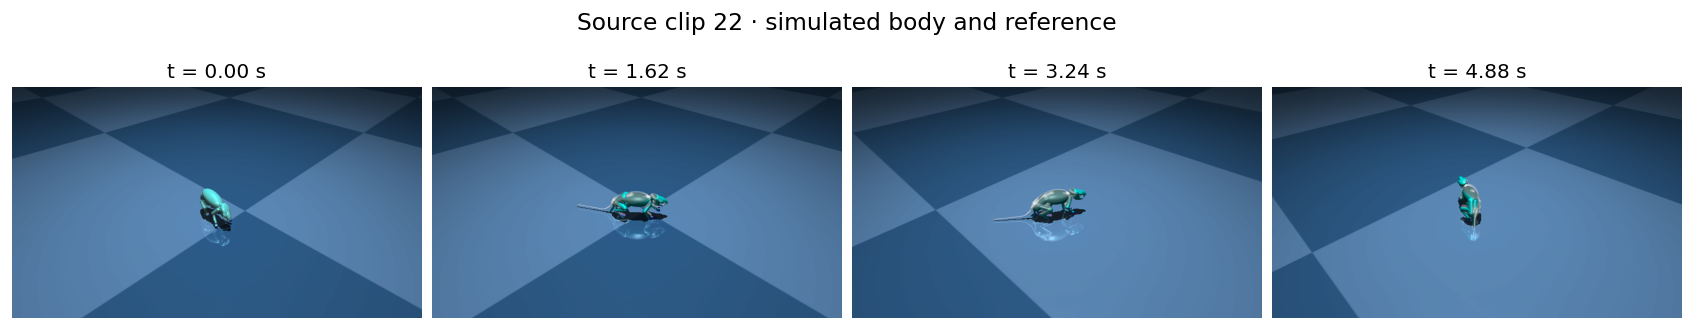

In [11]:
selected_frames = np.linspace(0, len(frames) - 1, 4, dtype=int)
fig, axes = plt.subplots(1, 4, figsize=(14, 3), layout="constrained")
for ax, frame_index in zip(axes, selected_frames, strict=True):
    ax.imshow(frames[frame_index])
    ax.set_title(f"t = {state_time[render_indices[frame_index]]:.2f} s")
    ax.axis("off")
fig.suptitle(f"Source clip {FOCUS_CLIP_ID} · simulated body and reference", fontsize=14)
fig.savefig(output_dir / "timelapse.pdf", bbox_inches="tight")
plt.show()

## 5. Measure tracking error and reward

Training seeks a policy that maximizes expected discounted reward:

$$J(\theta)=\mathbb E_{\pi_\theta}\left[\sum_{t=0}^{T-1}\gamma^t r_t\right].$$

Here $\gamma$ discounts future rewards and $T$ is the episode length. Tracking
terms reward agreement with the reference; control and energy costs penalize
expensive actions. For a Gaussian tracking term,

$$r_t^{(k)}=w_k\exp\left[-\tfrac12(d_t^{(k)}/\sigma_k)^2\right],$$

where $d_t^{(k)}$ is the error, $w_k$ the weight, and $\sigma_k$ the tolerance.
An error of $\sigma_k$ gives about $0.61w_k$; an error of $2\sigma_k$ gives
$0.14w_k$. Increasing the tolerance therefore makes the same error less costly.
See [the motion-imitation objective](https://arxiv.org/html/2511.20532v1#S4.SS4).

We plot the environment's root-position error, orientation error, and total reward.
The orientation metric measures quaternion distance in degrees. Total reward
combines several terms and costs, so a dip need not coincide with a peak in either
of these two errors.

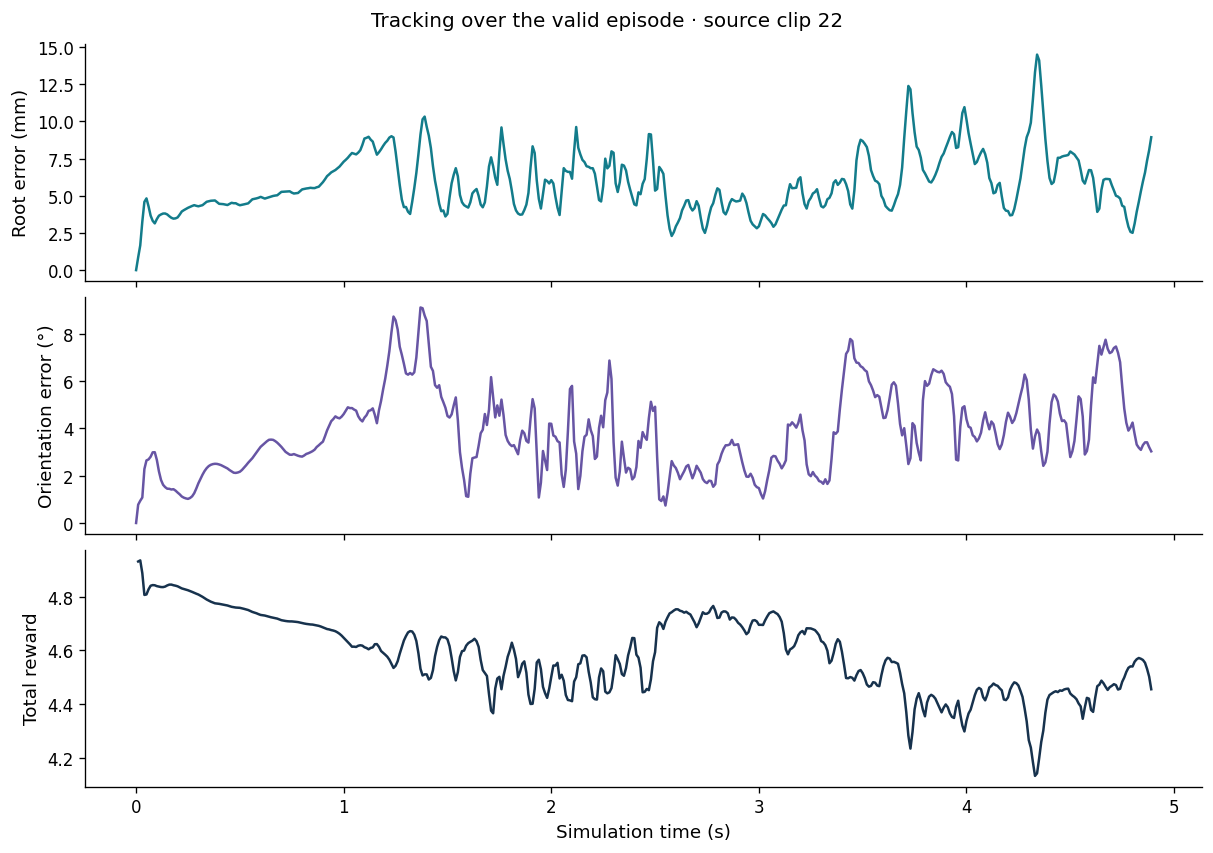

,source clip,duration (s),mean root error (mm),max root error (mm),mean orientation error (°),mean transition reward,failure termination
0,22,4.89001,5.830275,14.488742,3.807256,4.583686,False


In [12]:
time_valid = state_time[valid_states]
root_error_mm = np.asarray(states.metrics["root_pos_distance"])[valid_states] * 1000
orientation_error_deg = np.asarray(states.metrics["root_angular_error"])[valid_states]
reward_valid = single["state_rewards"][1 : last_state + 1]

fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True, layout="constrained")
axes[0].plot(time_valid, root_error_mm, color="#137c8b")
axes[0].set_ylabel("Root error (mm)")
axes[1].plot(time_valid, orientation_error_deg, color="#6755a4")
axes[1].set_ylabel("Orientation error (°)")
axes[2].plot(time_valid[1:], reward_valid, color="#17324d")
axes[2].set_ylabel("Total reward")
axes[2].set_xlabel("Simulation time (s)")
fig.suptitle(f"Tracking over the valid episode · source clip {FOCUS_CLIP_ID}")
fig.savefig(output_dir / "tracking_metrics.pdf", bbox_inches="tight")
plt.show()
display(
    pd.DataFrame(
        [
            {
                "source clip": FOCUS_CLIP_ID,
                "duration (s)": float(time_valid[-1]),
                "mean root error (mm)": float(root_error_mm.mean()),
                "max root error (mm)": float(root_error_mm.max()),
                "mean orientation error (°)": float(orientation_error_deg.mean()),
                "mean transition reward": float(reward_valid.mean()),
                "failure termination": failure,
            }
        ]
    )
)

### Compare individual joints

Root position and orientation describe the body's overall placement. Two poses
can agree on these quantities while placing a limb differently. Let's compare
the left and right elbows and shoulders:

$$\mathrm{RMSE}_j=\sqrt{\frac1N\sum_t(q_{tj}-q^{ref}_{tj})^2}.$$


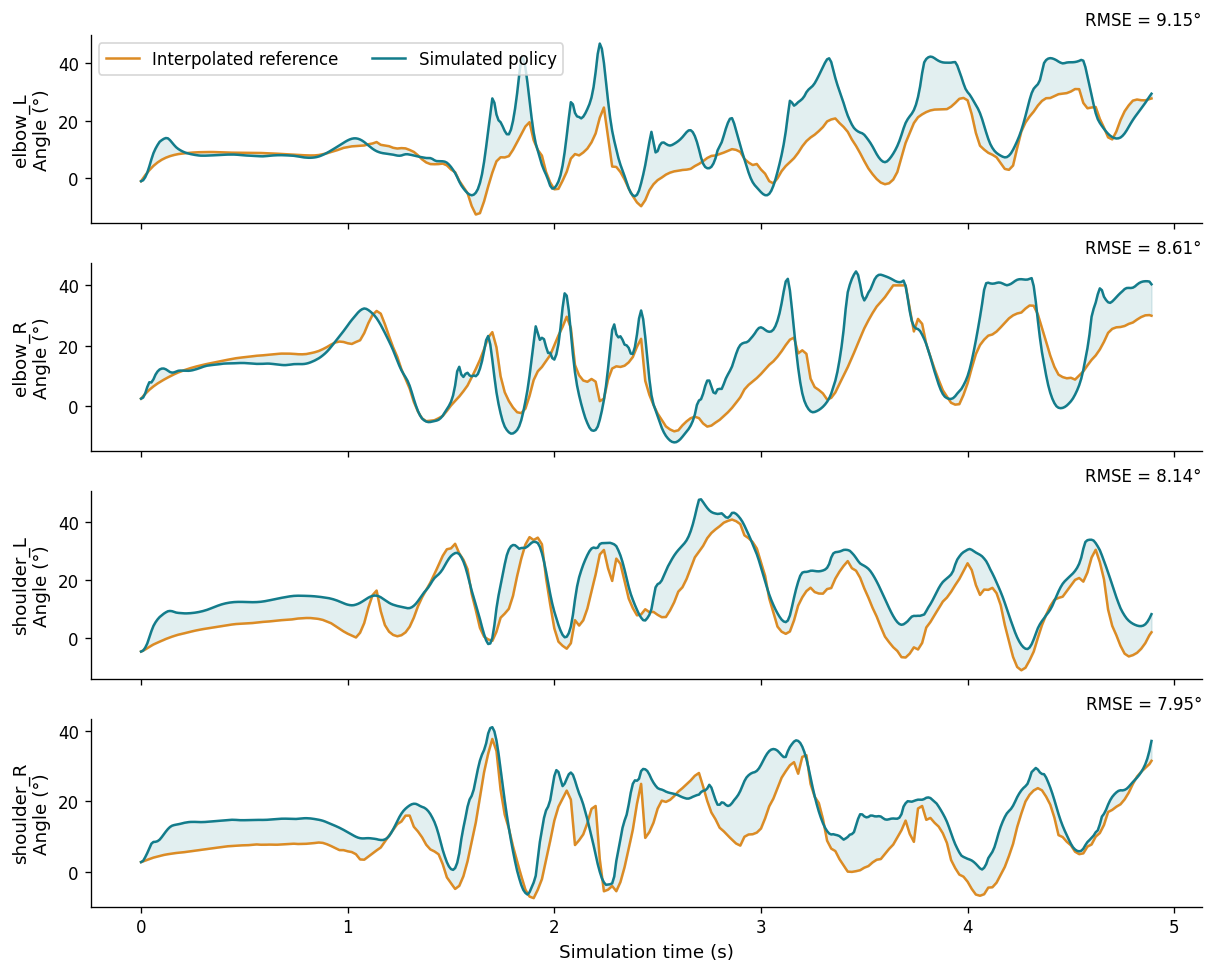

In [13]:
joint_labels = ["elbow_L", "elbow_R", "shoulder_L", "shoulder_R"]
joint_addresses = []
for label in joint_labels:
    joint_id = next(
        i
        for i in range(model.njnt)
        if model.joint(i).name == label or model.joint(i).name.startswith(label + "-")
    )
    assert model.jnt_type[joint_id] == mujoco.mjtJoint.mjJNT_HINGE
    joint_addresses.append(int(model.jnt_qposadr[joint_id]))

reference_angles = np.rad2deg(single["qposes_ref"][valid_states][:, joint_addresses])
simulated_angles = np.rad2deg(
    single["qposes_rollout"][valid_states][:, joint_addresses]
)
joint_rmse = np.sqrt(np.mean((simulated_angles - reference_angles) ** 2, axis=0))

fig, axes = plt.subplots(4, 1, figsize=(10, 8), sharex=True, layout="constrained")
for index, (ax, label) in enumerate(zip(axes, joint_labels, strict=True)):
    ax.plot(
        time_valid,
        reference_angles[:, index],
        color="#dc8b24",
        label="Interpolated reference",
    )
    ax.plot(
        time_valid,
        simulated_angles[:, index],
        color="#137c8b",
        label="Simulated policy",
    )
    ax.fill_between(
        time_valid,
        reference_angles[:, index],
        simulated_angles[:, index],
        color="#137c8b",
        alpha=0.12,
    )
    ax.set_ylabel(f"{label}\nAngle (°)")
    ax.set_title(f"RMSE = {joint_rmse[index]:.2f}°", loc="right", fontsize=10)
axes[0].legend(loc="upper left", ncols=2)
axes[-1].set_xlabel("Simulation time (s)")
fig.savefig(output_dir / "joint_tracking.pdf", bbox_inches="tight")
plt.show()

### Inspect actuator commands and sensors

The action heatmap shows when each actuator receives a positive or negative
command. The lower plot summarizes command magnitude with a root mean square
across actuators. Commands are normalized inputs to the body model. Their conversion to torque
depends on the actuator, so the plotted values are not torques in N·m.

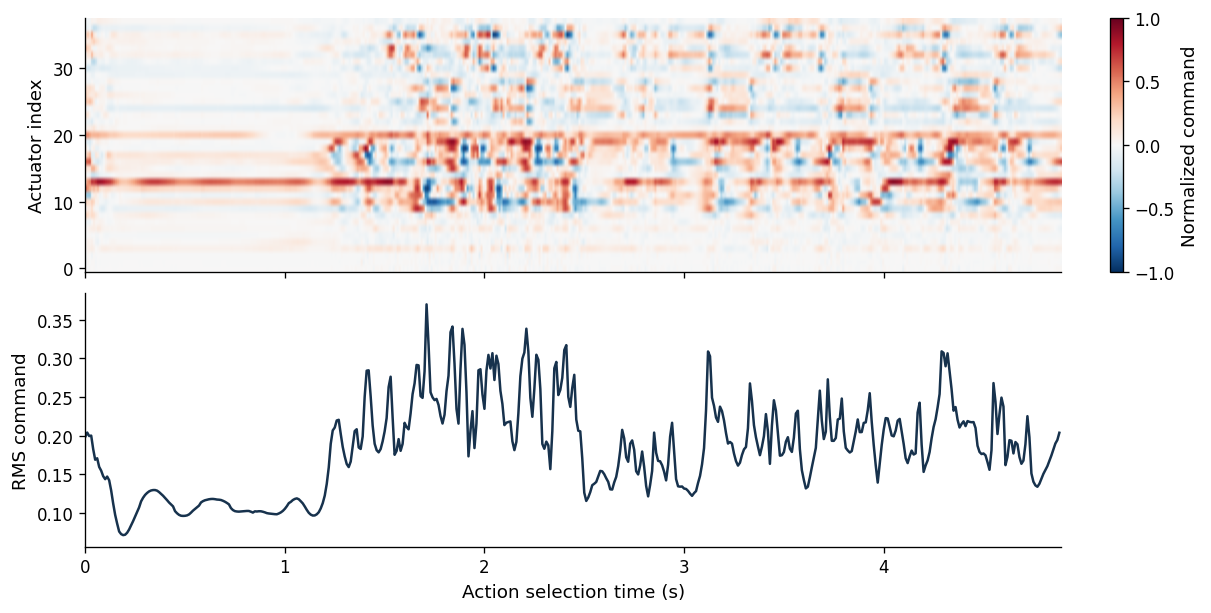

,sensor,address,dimensions
0,accelerometer-rodent,0,3
1,velocimeter-rodent,3,3
2,gyro-rodent,6,3
3,palm_L-rodent,9,1
4,palm_R-rodent,10,1
5,sole_L-rodent,11,1
6,sole_R-rodent,12,1
7,torso-rodent,13,3


Sensor readings: (498, 16) (transitions, sensor coordinates)
External body wrenches: (498, 68, 6) (transitions, bodies, 6)


In [14]:
controls = single["ctrl"][valid_actions]
action_time = state_time[:last_state]
fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True, layout="constrained")
im = axes[0].imshow(
    controls.T,
    aspect="auto",
    origin="lower",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    extent=(action_time[0], state_time[last_state], -0.5, controls.shape[1] - 0.5),
)
axes[0].set_ylabel("Actuator index")
fig.colorbar(im, ax=axes[0], label="Normalized command")
axes[1].plot(action_time, np.sqrt(np.mean(controls**2, axis=1)), color="#17324d")
axes[1].set_ylabel("RMS command")
axes[1].set_xlabel("Action selection time (s)")
fig.savefig(output_dir / "actions.pdf", bbox_inches="tight")
plt.show()
sensor_table = pd.DataFrame(
    [
        {
            "sensor": model.sensor(i).name,
            "address": int(model.sensor_adr[i]),
            "dimensions": int(model.sensor_dim[i]),
        }
        for i in range(model.nsensor)
    ]
)
display(sensor_table)
print(
    "Sensor readings:",
    single["sensor_readings"].shape,
    "(transitions, sensor coordinates)",
)
print(
    "External body wrenches:", single["joint_forces"].shape, "(transitions, bodies, 6)"
)

## 6. Inspect the intention trajectory

The encoder produces one 16-dimensional intention for each action. Enable
`get_activation=True` during inference and `log_activations=True` during rollout
to retain it. The table below lists the available activations and their shapes.

To view the intention trajectory, we fit **principal component analysis (PCA)** to
this episode, and project onto the first two directions. Each point represents one action; color gives its selection time. The axis labels
report the fraction of variance each component retains. Read these fractions
alongside the plot: a two-dimensional picture may omit much of the variation.
A cluster in this projection alone does not establish a distinct behavior.

,activation,shape
0,decoder/layer_0,"(498, 1024)"
1,decoder/layer_1,"(498, 1024)"
2,decoder/layer_2,"(498, 512)"
3,egocentric_obs,"(498, 277)"
4,encoder/layer_0,"(498, 2048)"
5,encoder/layer_1,"(498, 1024)"
6,encoder/layer_2,"(498, 1024)"
7,encoder/logvar,"(498, 16)"
8,encoder/mean,"(498, 16)"
9,intention,"(498, 16)"


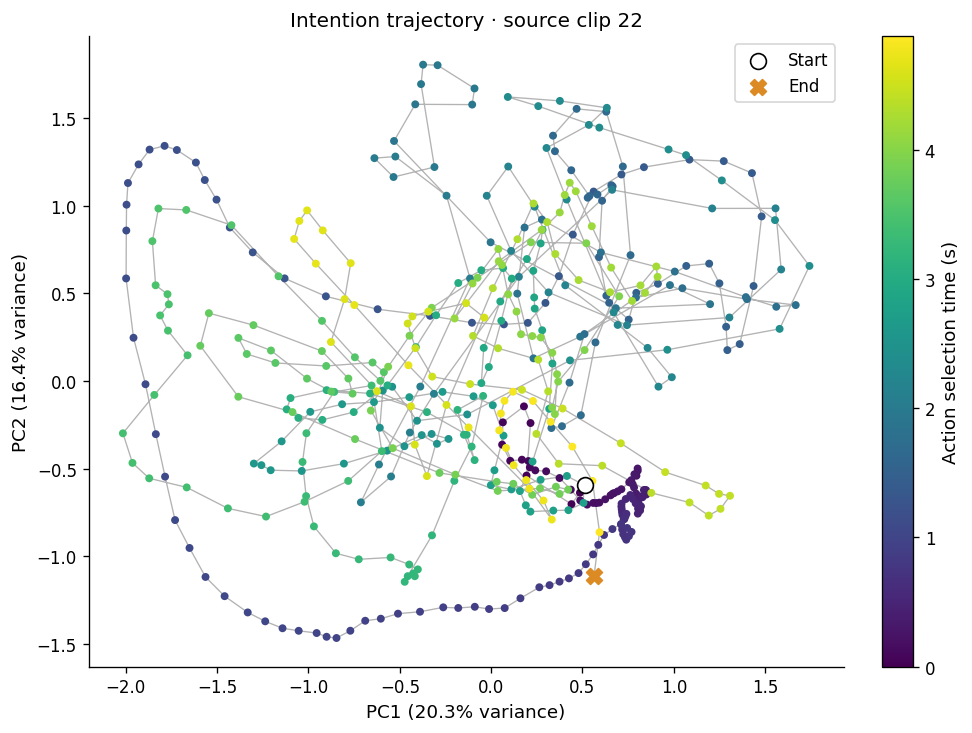

Variance retained in two components: 36.7%


In [15]:
display(
    pd.DataFrame(
        [
            {
                "activation": "/".join(str(part.key) for part in path),
                "shape": str(value.shape),
            }
            for path, value in jax.tree_util.tree_flatten_with_path(
                single["activations"]
            )[0]
        ]
    )
)
intentions = single["activations"]["intention"][valid_actions]
pca = PCA(n_components=2)
projection = pca.fit_transform(intentions)

fig, ax = plt.subplots(figsize=(8, 6), layout="constrained")
ax.plot(projection[:, 0], projection[:, 1], color="0.7", linewidth=0.8, zorder=1)
points = ax.scatter(
    projection[:, 0], projection[:, 1], c=action_time, cmap="viridis", s=14, zorder=2
)
ax.scatter(
    *projection[0],
    marker="o",
    s=90,
    facecolor="white",
    edgecolor="black",
    label="Start",
    zorder=3,
)
ax.scatter(*projection[-1], marker="X", s=90, color="#dc8b24", label="End", zorder=3)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
ax.set_title(f"Intention trajectory · source clip {FOCUS_CLIP_ID}")
ax.legend()
fig.colorbar(points, ax=ax, label="Action selection time (s)")
fig.savefig(output_dir / "intention_pca.pdf", bbox_inches="tight")
plt.show()
print(f"Variance retained in two components: {pca.explained_variance_ratio_.sum():.1%}")

## 7. Collect several clips

We have followed one trajectory through the policy and simulator. Now apply the
same rollout to all three clips with `jax.vmap`. Each returned array gains a
leading clip axis: positions have shape `(clips, states, coordinates)`.

We keep metrics and activations, but omit full states and sensors to reduce
memory use. For Warp, `num_worlds=BATCH_SIZE` allocates capacity for the parallel
worlds; `contacts_per_world` and `constraints_per_world` set the capacity per world.

Three clips with batch size two require batches `[0, 1]` and `[2, 2]` in local
indices. The duplicate keeps the compiled input shape fixed. We discard its
output before joining the batches. For a large dataset, save batches as they
finish instead of holding all results in memory.

In [16]:
batch_env = rollout.create_environment(cfg.env_config, num_worlds=BATCH_SIZE)
compact_generate = rollout.create_rollout_generator(
    cfg,
    batch_env,
    inference_fn,
    log_full_states=False,
    log_activations=True,
    log_metrics=True,
    log_sensor_data=False,
    init_hidden_fn=init_hidden_fn,
)
batch_generate = jax.jit(
    jax.vmap(lambda clip_index: compact_generate(clip_idx=clip_index, seed=SEED))
)

started = time.perf_counter()
batches = []
for start in range(0, len(source_ids), BATCH_SIZE):
    local_indices = np.arange(
        start, min(start + BATCH_SIZE, len(source_ids)), dtype=np.int32
    )
    padded_indices = np.pad(
        local_indices, (0, BATCH_SIZE - len(local_indices)), mode="edge"
    )
    batch = jax.device_get(batch_generate(jnp.asarray(padded_indices)))
    batches.append(
        jax.tree.map(lambda value, count=len(local_indices): value[:count], batch)
    )
batched = jax.tree.map(lambda *values: np.concatenate(values, axis=0), *batches)
batch_seconds = time.perf_counter() - started
print(
    f"Collected {len(source_ids)} clips in {batch_seconds:.2f} s (including first batch compilation)"
)
print("Coordinates:", batched["qposes_rollout"].shape, "(clips, states, coordinates)")
print(
    "Intentions:",
    batched["activations"]["intention"].shape,
    "(clips, actions, latent dimensions)",
)
assert batched["qposes_rollout"].shape[:2] == (len(source_ids), state_count)
assert all(np.isfinite(x).all() for x in jax.tree.leaves(batched))

batch_root_separation_mm = (
    np.linalg.norm(
        batched["qposes_rollout"][focus_index, : last_state + 1, :3]
        - single["qposes_rollout"][: last_state + 1, :3],
        axis=1,
    )
    * 1000
)
print(f"Max root separation, scalar vs batch: {batch_root_separation_mm.max():.3f} mm")

iterations: parent has 100 (default), child has 6, keeping parent value
ls_iterations: parent has 50 (default), child has 6, keeping parent value
solver: parent has 2 (default), child has 1, keeping parent value

/home/vyom/projects/vnl-playground/vnl_playground/tasks/rodent/base.py:155: UserWarning: Attach conflict when attaching 'rat', policy is 'warning'
iterations: parent has 100 (default), child has 6, keeping parent value
ls_iterations: parent has 50 (default), child has 6, keeping parent value
solver: parent has 2 (default), child has 1, keeping parent value
  self._mj_model = self._spec.compile()


Collected 3 clips in 178.94 s (including first batch compilation)
Coordinates: (3, 499, 74) (clips, states, coordinates)
Intentions: (3, 498, 16) (clips, actions, latent dimensions)
Max root separation, scalar vs batch: 2.574 mm


## 8. Train a policy or reuse its decoder

So far, the policy weights have stayed fixed. Training changes the weights to
improve behavior.

### Train by motion imitation

The rodent preset supplies the environment, network, and training settings:

```bash
python scripts/train.py --config-name rodent-full-clips
```

Track-MJX uses **proximal policy optimization (PPO)** to update the controller.
A critic learns to predict future return and helps estimate which actions improve
it. The loss combines the policy objective, value prediction, action entropy,
and optional latent penalties. The current latent penalties are

$$
L_{\rm KL}=\tfrac12\,\operatorname{mean}
  \left(\mu^2+\exp(\ell)-1-\ell\right),\qquad
L_{\rm temporal}=
\frac{\sum_t m_t\,\operatorname{mean}_d
  \left[(\mu_{t+1,d}-\mu_{t,d})^2\right]}{\max(\sum_t m_t,1)}.
$$

The first is a Gaussian KL penalty toward a standard normal latent distribution.
The second penalizes changes in adjacent latent means; $m_t$ excludes episode
boundaries. See [the implemented losses](../track_mjx/agent/ff_ppo/losses.py).

Logging includes rewards, videos, and optional activation histograms through
`logging_config.log_histograms`. To resume training, download the training-state
files omitted above. Resumption restores optimizer and normalizer state as well
as the saved environment-step count; evaluation-only files are insufficient.

### Reuse the decoder on another task

A direct task policy maps observations to actuator commands. Alternatively, train
a high-level policy to produce intentions and pass them to the frozen imitation
decoder:

$$o_t^{task}\ \longrightarrow\ z_t\ \longrightarrow\
D_{\rm frozen}(z_t,p_t)\ \longrightarrow\ a_t.$$

The decoder already maps intentions and proprioception to commands. The new policy
learns which intentions help solve its task. From the repository root:

```bash
python scripts/train_task.py --task RodentBowlEscape
python scripts/train_highlvl.py --task RodentBowlEscape \
  --mimic_checkpoint /absolute/path/to/feedforward_checkpoint
```

The first command trains a direct policy with Brax PPO; the second trains the
high-level policy. This decoder-transfer path supports feedforward policies.
The task must match the decoder's body, proprioception, action convention, and
control rate. Use `--help` for available overrides.

### Change the body model

Other animals use the same environment–policy–rollout workflow:

| Animal | Imitation task | Preset / reference data |
|---|---|---|
| Rodent | `RodentImitation` | `rodent-full-clips` / `data/rodent/rodent_reference_clips.h5` |
| Fruit fly | `FruitflyImitation` | `fly` / `data/fly/fly_reference_clip.h5` |
| Mouse arm | `MouseImitation` | Task defaults / `data/mouse_arm/` |
| Stick insect | `StickImitation` | Task defaults / `data/stick/stick_mesh_reference.h5` |
| Worm | `WormImitation` | `celegans` / `data/worm/celegans_ik_only_04182019am_centerline_locomotion_2d.h5` |

Choose a compatible policy and reference file together. Each body has its own
coordinates, sensors, timing, and actuators.

**Further reading:** [MIMIC-MJX paper](https://arxiv.org/abs/2511.20532),
[rollout API](../track_mjx/analysis/rollout.py),
[checkpoint API](../track_mjx/agent/checkpointing.py).